<a href="https://colab.research.google.com/github/LAF1225/CSRx-Research-Scripts/blob/main/Group_2_Gaia_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
df = pd.read_csv('group1_cleaned_gaia_data_98500.csv')

In [ ]:
df

,source_id,parallax,parallax_error,phot_g_mean_mag,bp_rp,phot_bp_mean_mag,phot_rp_mean_mag,parallax_error_frac,distance_pc,abs_g_mag,log_L,Teff,spectral_type,luminosity_class,MK_class
0,5.912321e+18,0.422564,0.050442,16.401175,0.867209,16.751710,15.884501,0.119371,2366.504360,4.530638,0.055745,4809.383521,K,Main Sequence,KMain Sequence
1,5.912321e+18,0.179850,0.019719,14.225386,1.400027,14.858905,13.458878,0.109640,5560.204260,0.499932,1.668027,3690.406643,M,Giant,MGiant
2,5.912321e+18,1.255950,0.158335,18.220974,2.044258,19.266665,17.222406,0.126068,796.209999,8.715836,-1.618334,2716.911889,M,Main Sequence,MMain Sequence
3,2.267709e+18,1.545277,0.012220,13.765941,0.933922,14.148946,13.215024,0.007908,647.133024,4.710973,-0.016389,4649.861082,K,Main Sequence,KMain Sequence
4,2.267709e+18,3.566535,0.123013,18.221603,2.417293,19.523788,17.106495,0.034491,280.384156,10.982836,-2.525134,2291.394065,M,Main Sequence,MMain Sequence
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98546,5.917120e+18,0.447917,0.071525,16.329044,1.306489,16.709553,15.403064,0.159683,2232.556726,4.585031,0.033987,3863.108287,K,Main Sequence,KMain Sequence
98547,5.917116e+18,0.331938,0.065933,16.703154,1.323867,17.281631,15.957765,0.198632,3012.611830,4.308438,0.144625,3830.329676,K,Main Sequence,KMain Sequence
98548,4.125938e+18,1.335493,0.254925,18.911772,3.028030,20.640380,17.612350,0.190884,748.787236,9.539980,-1.947992,1753.043251,M,Main Sequence,MMain Sequence
98549,4.126025e+18,0.400301,0.028823,14.014679,1.591845,14.760107,13.168263,0.072003,2498.120032,2.026612,1.057355,3363.412373,M,Subgiant,MSubgiant


In [ ]:
#data cleaning
import numpy as np
key_columns = [
    'parallax', 'parallax_error',
    'phot_g_mean_mag', 'phot_bp_mean_mag','phot_rp_mean_mag','bp_rp'
]
df = df.dropna(subset=key_columns)
df = df[np.isfinite(df[key_columns]).all(axis=1)]
df = df[df['parallax']>0]
df['parallax_error_frac'] = df['parallax_error'] / df['parallax']
df = df[df['parallax_error_frac']<0.2]
df = df[
    (df['phot_g_mean_mag']>0) & (df['phot_g_mean_mag']<25) & (df['bp_rp']>-0.5) & (df['bp_rp']<4.5)
]
df = df[
    (df['phot_bp_mean_mag']>0) & (df['phot_rp_mean_mag']>0)
]
df = df.reset_index(drop=True)
print(f"✔ Cleaned dataset contains {len(df)}stars.")


✔ Cleaned dataset contains 98551stars.


In [ ]:
#Classifying and cleaning data
import numpy as np
import pandas as pd
df['distance_pc'] = 1000 / df['parallax']
df['abs_g_mag'] = df['phot_g_mean_mag'] - 5 * np.log10(df['distance_pc']/10)
df['log_L'] = -0.4 * (df['abs_g_mag'] - 4.67)
bp_rp = df['bp_rp']
log_Teff = 3.879 - 0.234 * bp_rp + 0.008 * bp_rp ** 2
df['Teff'] = 10 ** log_Teff
def classify_spectral_type(teff):
    if teff > 30000:
        return 'O'
    elif teff > 10000:
        return 'B'
    elif teff > 7500:
        return 'A'
    elif teff > 6000:
        return 'F'
    elif teff > 5200:
        return 'G'
    elif teff > 3700:
        return 'K'
    else:
        return 'M'
df['spectral_type'] = df['Teff'].apply(classify_spectral_type)
def is_white_dwarf(Teff, abs_mag):
    return abs_mag > 12 and Teff > 6000
def classify_luminosity_class(Teff, abs_mag):
    if is_white_dwarf(Teff, abs_mag):
        return 'White Dwarf'
    elif abs_mag < 2:
        return 'Giant'
    elif 16 >abs_mag > 4:
        return 'Main Sequence'
    elif 2 <= abs_mag <= 4:
        return 'Subgiant'
    else:
        return 'Other'
df['luminosity_class'] = df.apply(lambda row: classify_luminosity_class(row['Teff'], row['abs_g_mag']), axis=1)
df['MK_class'] = df['spectral_type'] + df['luminosity_class']
df[['source_id', 'parallax', 'bp_rp', 'phot_g_mean_mag', 'abs_g_mag', 'Teff', 'log_L', 'spectral_type', 'luminosity_class', 'MK_class']].head()

,source_id,parallax,bp_rp,phot_g_mean_mag,abs_g_mag,Teff,log_L,spectral_type,luminosity_class,MK_class
0,5.912321e+18,0.422564,0.867209,16.401175,4.530638,4809.383521,0.055745,K,Main Sequence,KMain Sequence
1,5.912321e+18,0.179850,1.400027,14.225386,0.499932,3690.406643,1.668027,M,Giant,MGiant
2,5.912321e+18,1.255950,2.044258,18.220974,8.715836,2716.911889,-1.618334,M,Main Sequence,MMain Sequence
3,2.267709e+18,1.545277,0.933922,13.765941,4.710973,4649.861082,-0.016389,K,Main Sequence,KMain Sequence
4,2.267709e+18,3.566535,2.417293,18.221603,10.982836,2291.394065,-2.525134,M,Main Sequence,MMain Sequence


NameError: name 'region_colors' is not defined

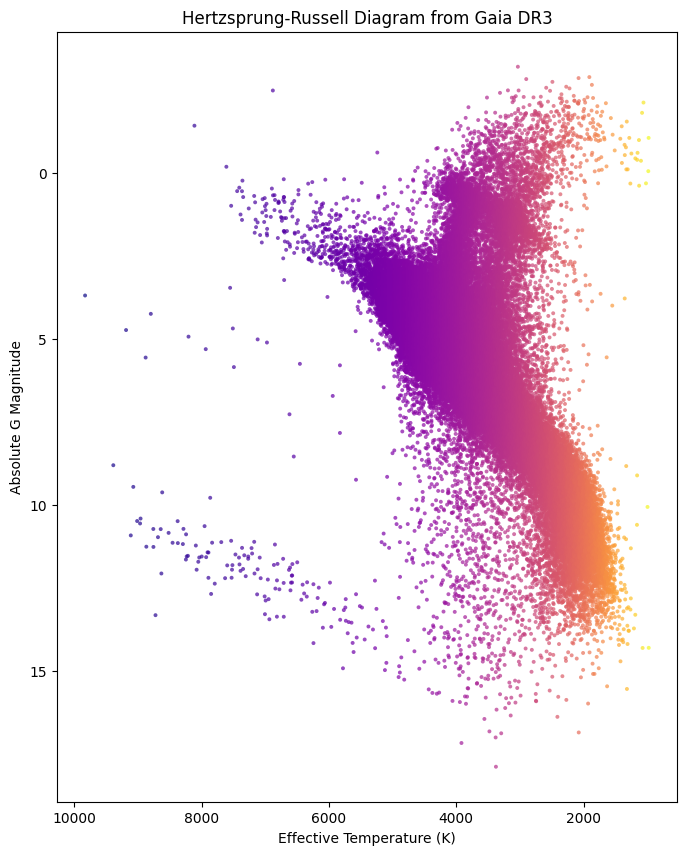

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


plt.figure(figsize=(8, 10))
scatter = plt.scatter(
   df['Teff'],
   df['abs_g_mag'],
   c=df['bp_rp'],
   cmap='plasma',
   s=8,
   alpha=0.7,
   edgecolors='none'
)


plt.gca().invert_xaxis()  # Temperature decreases to the right
plt.gca().invert_yaxis()  # Bright stars at the top


plt.xlabel('Effective Temperature (K)')
plt.ylabel('Absolute G Magnitude')
plt.title('Hertzsprung-Russell Diagram from Gaia DR3')


legend_elements = [Line2D([0], [0], marker='o', color='w', label=label,
                          markerfacecolor=color, markersize=6)
                   for label, color in region_colors.items()]
plt.legend(handles=legend_elements, title='Stellar Region')

cbar = plt.colorbar(scatter, label='BP - RP Color')
plt.grid(True)
plt.tight_layout()
plt.show()



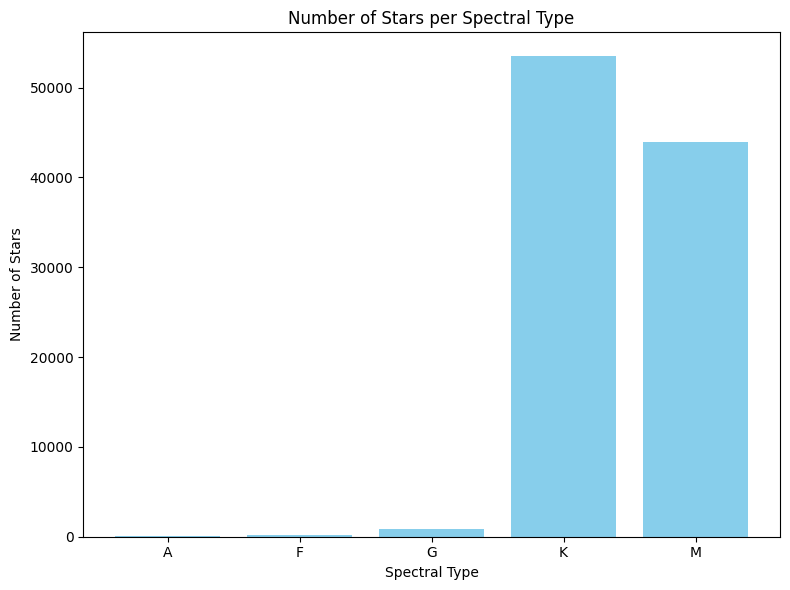

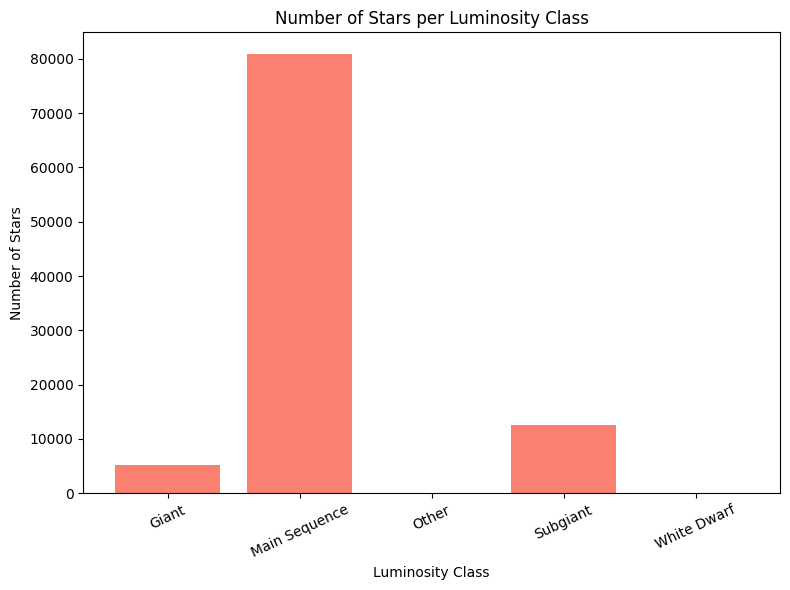

In [ ]:
import matplotlib.pyplot as plt

#stars as spectral type
spectral_counts = df['spectral_type'].value_counts().sort_index()

plt.figure(figsize=(8,6))
plt.bar(spectral_counts.index, spectral_counts.values, color='skyblue')
plt.xlabel('Spectral Type')
plt.ylabel('Number of Stars')
plt.title('Number of Stars per Spectral Type')
plt.tight_layout()
plt.show()


# luminosity
luminosity_counts = df['luminosity_class'].value_counts().sort_index()

plt.figure(figsize=(8,6))
plt.bar(luminosity_counts.index, luminosity_counts.values, color='salmon')
plt.xlabel('Luminosity Class')
plt.ylabel('Number of Stars')
plt.title('Number of Stars per Luminosity Class')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

#There are white dwarfs, but the number is so small that it isn't visible on the graph

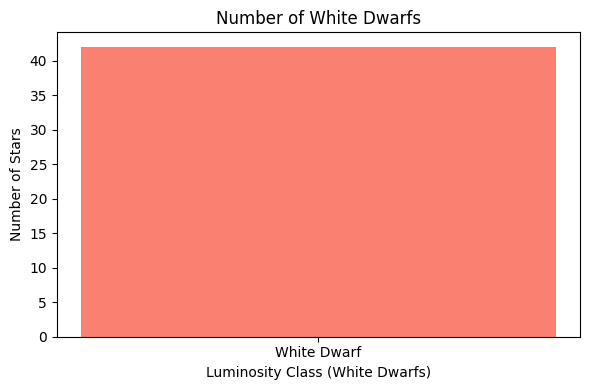

In [ ]:
import matplotlib.pyplot as plt

white_dwarfs = df[df['luminosity_class'] == 'White Dwarf']

wd_luminosity_counts = white_dwarfs['luminosity_class'].value_counts().sort_index()

plt.figure(figsize=(6,4))
plt.bar(wd_luminosity_counts.index, wd_luminosity_counts.values, color='salmon')
plt.xlabel('Luminosity Class (White Dwarfs)')
plt.ylabel('Number of Stars')
plt.title('Number of White Dwarfs')
plt.tight_layout()
plt.show()


In [ ]:
from sklearn.ensemble import IsolationForest
import numpy as np
import pandas as pd

anomaly_inputs = ['Teff', 'log_L', 'bp_rp']
model_IF = IsolationForest(n_estimators=500, contamination=0.05, random_state=42)
model_IF.fit(df[anomaly_inputs])
df['anomaly_score'] = model_IF.decision_function(df[anomaly_inputs])
df['anomaly'] = model_IF.predict(df[anomaly_inputs])
df.loc[:, ['Teff', 'log_L', 'bp_rp','anomaly_score','anomaly']]

,Teff,log_L,bp_rp,anomaly_score,anomaly
0,4809.383521,0.055745,0.867209,0.140589,1
1,3690.406643,1.668027,1.400027,0.024614,1
2,2716.911889,-1.618334,2.044258,0.109117,1
3,4649.861082,-0.016389,0.933922,0.164614,1
4,2291.394065,-2.525134,2.417293,0.055707,1
...,...,...,...,...,...
98546,3863.108287,0.033987,1.306489,0.162439,1
98547,3830.329676,0.144625,1.323867,0.154356,1
98548,1753.043251,-1.947992,3.028030,-0.058708,-1
98549,3363.412373,1.057355,1.591845,0.067574,1


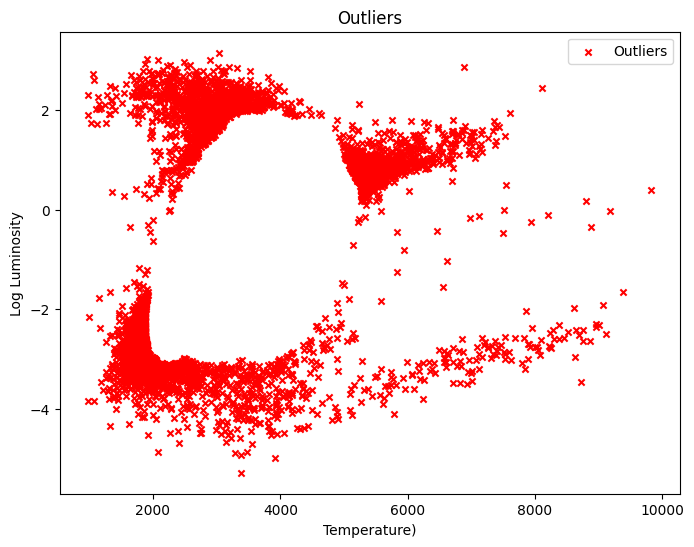

In [ ]:
import matplotlib.pyplot as plt #this is just a test graph for luminosity vs teff

plt.figure(figsize=(8,6))

plt.scatter(
    df.loc[df['anomaly'] == -1, 'Teff'],
    df.loc[df['anomaly'] == -1, 'log_L'],
    c='red', label='Outliers', s=20, marker='x'
)

plt.xlabel('Temperature)')
plt.ylabel('Log Luminosity')
plt.title('Outliers')
plt.legend()
plt.show()


In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

def outlierplot(data, graph_title, x_var, y_var, x_axis_limits=[0,1], y_axis_limits=[0,1]):
    print("Number of anomalies:", len(data[data['anomaly'] == -1]))
    print("Number of normal values:", len(data[data['anomaly'] == 1]))
    print("Number of total values:", len(data))

    g = sns.FacetGrid(data, col='anomaly', height=4, hue="anomaly", hue_order=[1, -1])
    g.map(sns.scatterplot, x_var, y_var)
    g.fig.suptitle(f'Graph Title: {graph_title}', y=1.10, fontweight='bold')
    g.set(xlim=x_axis_limits, ylim=y_axis_limits)

    axes = g.axes.flatten()
    axes[1].set_title(f"Inliers\n{len(data[data['anomaly'] == 1])} points")
    axes[0].set_title(f"Outliers\n{len(data[data['anomaly'] == -1])} points")

    return g

Number of anomalies: 4928
Number of normal values: 93623
Number of total values: 98551
Number of anomalies: 4928
Number of normal values: 93623
Number of total values: 98551
Number of anomalies: 4928
Number of normal values: 93623
Number of total values: 98551


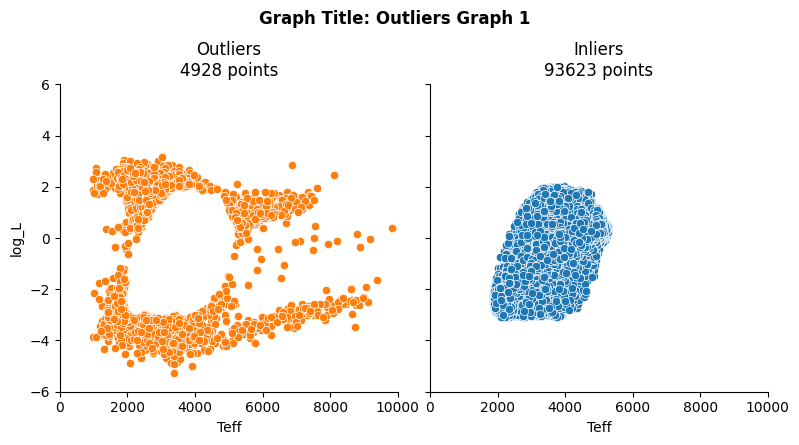

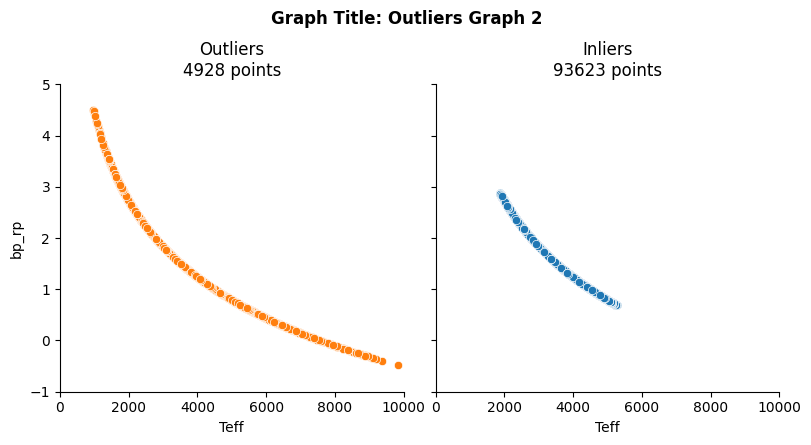

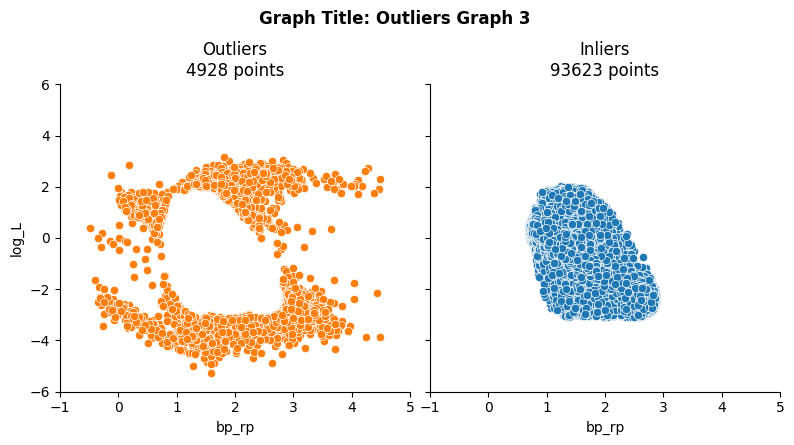

In [ ]:
outlierplot(df, "Outliers Graph 1", "Teff", "log_L", [0,10000], [-6,6])
outlierplot(df, "Outliers Graph 2", "Teff", "bp_rp", [0,10000], [-1,5])
outlierplot(df, "Outliers Graph 3", "bp_rp", "log_L", [-1,5], [-6,6])

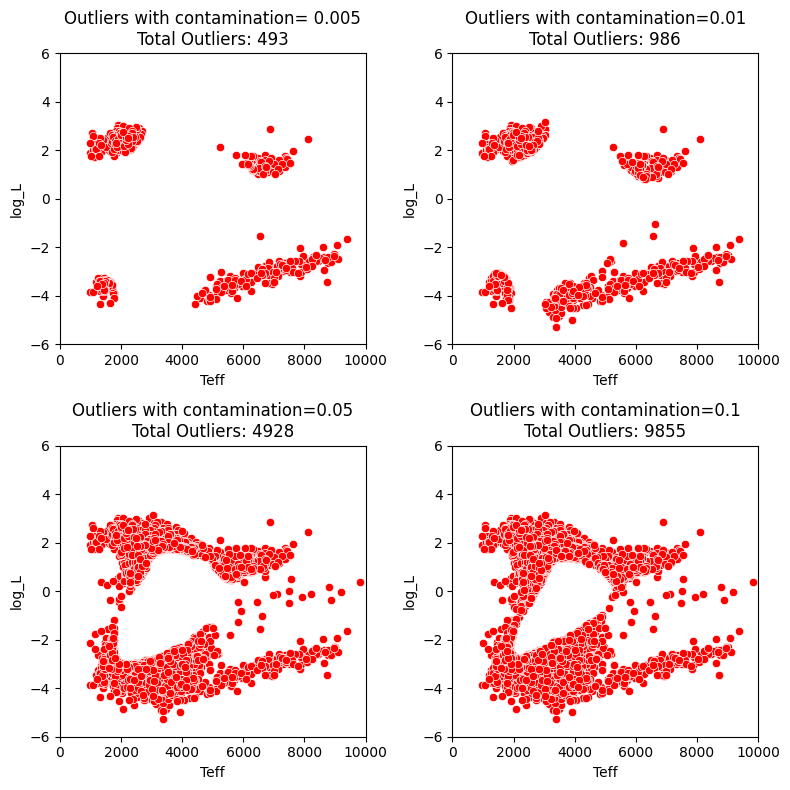

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest

contamination_values = [0.005, 0.01, 0.05, 0.1]
anomaly_inputs = ['Teff', 'log_L']
fig, axes = plt.subplots(2,2, figsize=(8,8))
axes = axes.flatten()
titles = ["Outliers with contamination= 0.005", "Outliers with contamination=0.01", "Outliers with contamination=0.05", "Outliers with contamination=0.1"]

for i in range(4):
  contamination = contamination_values[i]
  temp_df = df.copy()
  model_IF = IsolationForest(n_estimators=500, contamination=contamination, random_state=42)
  model_IF.fit(temp_df[anomaly_inputs])
  temp_df['anomaly_score'] = model_IF.decision_function(temp_df[anomaly_inputs])
  temp_df['anomaly'] = model_IF.predict(temp_df[anomaly_inputs])
  outliers_df= temp_df[temp_df['anomaly'] == -1]
  ax = axes[i]
  sns.scatterplot(
      data=outliers_df,
      x='Teff',
      y='log_L',
      color='red',
      ax=ax
    )
  ax.set_title(f"{titles[i]}\nTotal Outliers: {len(outliers_df)}")
  ax.set_xlim(0, 10000)
  ax.set_ylim(-6, 6)

plt.tight_layout()
plt.show()



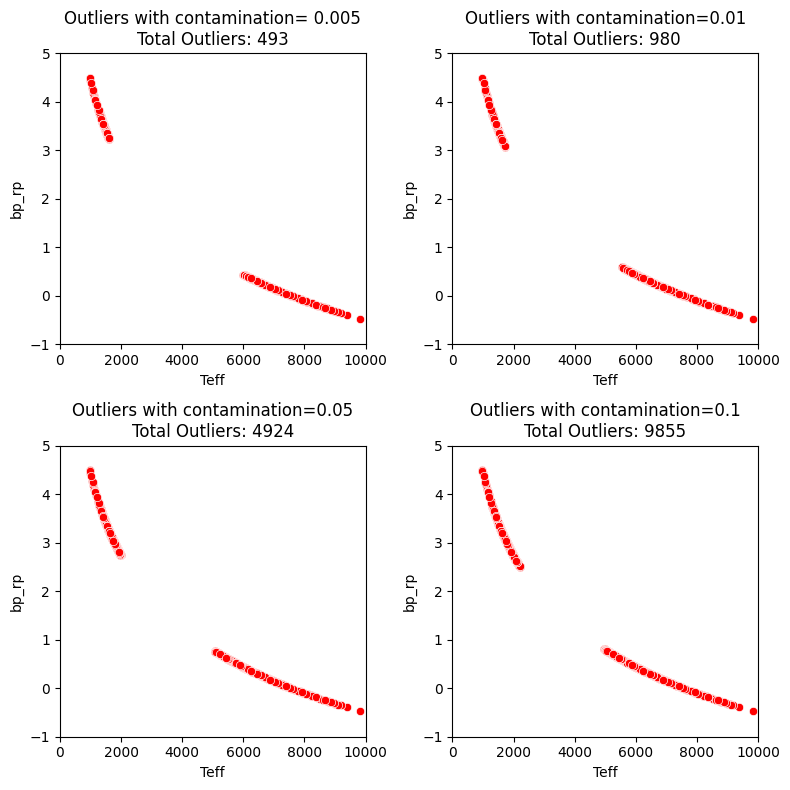

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest

contamination_values = [0.005, 0.01, 0.05, 0.1]
anomaly_inputs = ['Teff', 'bp_rp']
fig, axes = plt.subplots(2,2, figsize=(8,8))
axes = axes.flatten()
titles = ["Outliers with contamination= 0.005", "Outliers with contamination=0.01", "Outliers with contamination=0.05", "Outliers with contamination=0.1"]

for i in range(4):
  contamination = contamination_values[i]
  temp_df = df.copy()
  model_IF = IsolationForest(n_estimators=500, contamination=contamination, random_state=42)
  model_IF.fit(temp_df[anomaly_inputs])
  temp_df['anomaly_score'] = model_IF.decision_function(temp_df[anomaly_inputs])
  temp_df['anomaly'] = model_IF.predict(temp_df[anomaly_inputs])
  outliers_df= temp_df[temp_df['anomaly'] == -1]
  ax = axes[i]
  sns.scatterplot(
      data=outliers_df,
      x='Teff',
      y='bp_rp',
      color='red',
      ax=ax
    )
  ax.set_title(f"{titles[i]}\nTotal Outliers: {len(outliers_df)}")
  ax.set_xlim(0, 10000)
  ax.set_ylim(-1, 5)

plt.tight_layout()
plt.show()

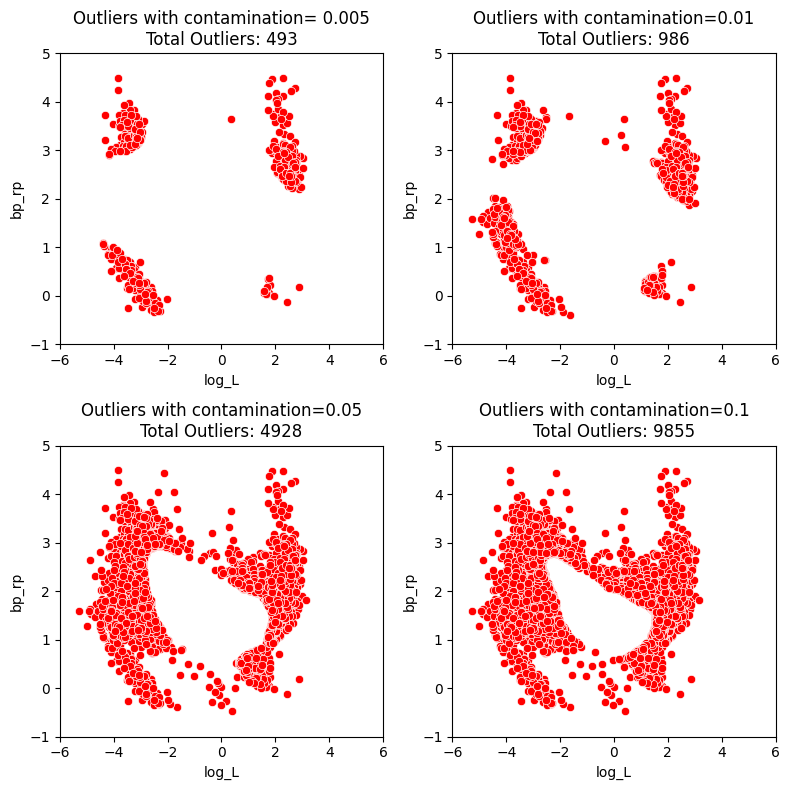

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest

contamination_values = [0.005, 0.01, 0.05, 0.1]
anomaly_inputs = ['log_L', 'bp_rp']
fig, axes = plt.subplots(2,2, figsize=(8,8))
axes = axes.flatten()
titles = ["Outliers with contamination= 0.005", "Outliers with contamination=0.01", "Outliers with contamination=0.05", "Outliers with contamination=0.1"]

for i in range(4):
  contamination = contamination_values[i]
  temp_df = df.copy()
  model_IF = IsolationForest(n_estimators=500, contamination=contamination, random_state=42)
  model_IF.fit(temp_df[anomaly_inputs])
  temp_df['anomaly_score'] = model_IF.decision_function(temp_df[anomaly_inputs])
  temp_df['anomaly'] = model_IF.predict(temp_df[anomaly_inputs])
  outliers_df= temp_df[temp_df['anomaly'] == -1]
  ax = axes[i]
  sns.scatterplot(
      data=outliers_df,
      x='log_L',
      y='bp_rp',
      color='red',
      ax=ax
    )
  ax.set_title(f"{titles[i]}\nTotal Outliers: {len(outliers_df)}")
  ax.set_xlim(-6, 6)
  ax.set_ylim(-1, 5)

plt.tight_layout()
plt.show()

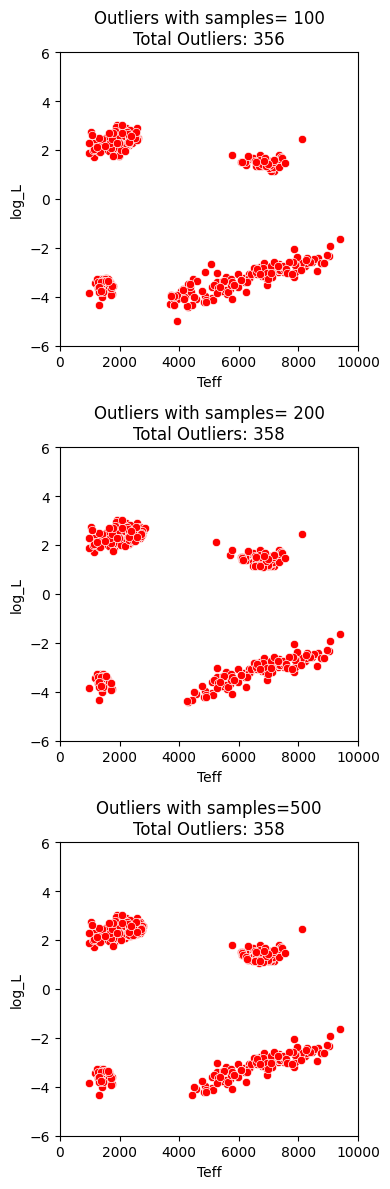

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest

estimator_values = [100, 200, 500]
anomaly_inputs = ['Teff', 'log_L']
fig, axes = plt.subplots(3,1, figsize=(4,12))
axes = axes.flatten()
titles = ["Outliers with samples= 100", "Outliers with samples= 200", "Outliers with samples=500"]

for i in range(3):
  estimator_value = estimator_values[i]
  temp_df = df.copy()
  model_IF = IsolationForest(n_estimators= estimator_value, contamination= 0.005, random_state=42)
  model_IF.fit(temp_df[anomaly_inputs])
  temp_df['anomaly_score'] = model_IF.decision_function(temp_df[anomaly_inputs])
  temp_df['anomaly'] = model_IF.predict(temp_df[anomaly_inputs])
  outliers_df= temp_df[temp_df['anomaly'] == -1]
  ax = axes[i]
  sns.scatterplot(
      data=outliers_df,
      x='Teff',
      y='log_L',
      color='red',
      ax=ax
    )
  ax.set_title(f"{titles[i]}\nTotal Outliers: {len(outliers_df)}")
  ax.set_xlim(0, 10000)
  ax.set_ylim(-6, 6)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn import metrics
from sklearn.metrics import pairwise_distances
from sklearn import datasets
X = df[['Teff', 'log_L']]
import numpy as np
from sklearn.cluster import KMeanswe
kmeans_model = KMeans(n_clusters=2, random_state=1).fit(X)
labels = kmeans_model.labels_
metrics.silhouette_score(X, labels, metric='euclidean')


NameError: name 'df' is not defined

In [ ]:
# VARIED ESTIMATOR VALUES
from sklearn.metrics import silhouette_score
from sklearn.ensemble import IsolationForest
import numpy as np
import pandas as pd

# Assuming 'df' is your DataFrame with features: Teff, log_L, and anomalies detected

# Select features for Isolation Forest
anomaly_inputs = ['Teff', 'bp_rp', 'log_L']

# List of n_estimators and contamination values to test
n_estimators_values = [100, 200, 500]
contamination_levels = [0.005]

# Store results for Silhouette Scores
silhouette_results = []

# Loop over all combinations of n_estimators and contamination
for n_estimators in n_estimators_values:
    for contamination in contamination_levels:
        # Run the model 6 times for each combination
        silhouette_scores = []  # To store Silhouette Scores for each run

        for _ in range(6):
            # Create and fit the Isolation Forest model
            model_IF = IsolationForest(n_estimators=n_estimators, contamination=contamination, max_samples=256, random_state=42)
            model_IF.fit(df[anomaly_inputs])

            # Predict anomalies (-1 = outlier, 1 = normal)
            df['anomaly'] = model_IF.predict(df[anomaly_inputs])

            # Convert to binary labels: 1 for normal, 0 for anomaly
            labels = [1 if x == -1 else 0 for x in df['anomaly']]  # 1 = normal, 0 = anomaly

            # Calculate Silhouette Score for this run
            score = silhouette_score(df[anomaly_inputs], labels)
            silhouette_scores.append(score)

        # Calculate the average Silhouette Score for this combination of n_estimators and contamination
        avg_score = np.mean(silhouette_scores)

        # Store the result
        silhouette_results.append({
            'n_estimators': n_estimators,
            'contamination': contamination,
            'average_silhouette_score': avg_score,
            'individual_scores': silhouette_scores  # Store individual scores for reference
        })

        # Print the average score for each combination
        print(f"Average Silhouette Score for n_estimators={n_estimators}, contamination={contamination}: {avg_score:.4f}")

# Convert results to DataFrame for easy comparison
silhouette_df = pd.DataFrame(silhouette_results)
silhouette_df = silhouette_df.sort_values(by='average_silhouette_score', ascending=False)

# Show top results
print("\nTop Average Silhouette Scores:")
print(silhouette_df[['n_estimators', 'contamination', 'average_silhouette_score']].head())

Average Silhouette Score for n_estimators=100, contamination=0.005: 0.6362
Average Silhouette Score for n_estimators=200, contamination=0.005: 0.6308
Average Silhouette Score for n_estimators=500, contamination=0.005: 0.6334

Top Average Silhouette Scores:
   n_estimators  contamination  average_silhouette_score
0           100          0.005                  0.636151
2           500          0.005                  0.633435
1           200          0.005                  0.630808


In [ ]:
# VARIED ESTIMATOR VALUES
from sklearn.metrics import silhouette_score
from sklearn.ensemble import IsolationForest
import numpy as np
import pandas as pd

# Assuming 'df' is your DataFrame with features: Teff, log_L, and anomalies detected

# Select features for Isolation Forest
anomaly_inputs = ['Teff', 'bp_rp', 'log_L']

# List of n_estimators and contamination values to test
n_estimators_values = [500]
contamination_levels = [0.005, 0.01, 0.05, 0.1]

# Store results for Silhouette Scores
silhouette_results = []

# Loop over all combinations of n_estimators and contamination
for contamination in contamination_levels:
  for n_estimators in n_estimators_values:
        # Run the model 6 times for each combination
        silhouette_scores = []  # To store Silhouette Scores for each run

        for _ in range(6):
            # Create and fit the Isolation Forest model
            model_IF = IsolationForest(n_estimators=n_estimators, contamination=contamination, max_samples=256, random_state=42)
            model_IF.fit(df[anomaly_inputs])

            # Predict anomalies (-1 = outlier, 1 = normal)
            df['anomaly'] = model_IF.predict(df[anomaly_inputs])

            # Convert to binary labels: 1 for normal, 0 for anomaly
            labels = [1 if x == -1 else 0 for x in df['anomaly']]  # 1 = normal, 0 = anomaly

            # Calculate Silhouette Score for this run
            score = silhouette_score(df[anomaly_inputs], labels)
            silhouette_scores.append(score)

        # Calculate the average Silhouette Score for this combination of n_estimators and contamination
        avg_score = np.mean(silhouette_scores)

        # Store the result
        silhouette_results.append({
            'n_estimators': n_estimators,
            'contamination': contamination,
            'average_silhouette_score': avg_score,
            'individual_scores': silhouette_scores  # Store individual scores for reference
        })

        # Print the average score for each combination
        print(f"Average Silhouette Score for n_estimators={n_estimators}, contamination={contamination}: {avg_score:.4f}")

# Convert results to DataFrame for easy comparison
silhouette_df = pd.DataFrame(silhouette_results)
silhouette_df = silhouette_df.sort_values(by='average_silhouette_score', ascending=False)

# Show top results
print("\nTop Average Silhouette Scores:")
print(silhouette_df[['n_estimators', 'contamination', 'average_silhouette_score']].head())

Average Silhouette Score for n_estimators=500, contamination=0.005: 0.6334
Average Silhouette Score for n_estimators=500, contamination=0.01: 0.5686
Average Silhouette Score for n_estimators=500, contamination=0.05: 0.3809
Average Silhouette Score for n_estimators=500, contamination=0.1: 0.3255

Top Average Silhouette Scores:
   n_estimators  contamination  average_silhouette_score
0           500          0.005                  0.633435
1           500          0.010                  0.568633
2           500          0.050                  0.380876
3           500          0.100                  0.325545
